# Práctica: Aprendizaje por Refuerzo con el Juego del Gato
### Implementando Q-Learning desde cero

**Objetivo general:** que un agente aprenda a jugar al gato *por sí mismo*, únicamente a base de prueba y error, usando el algoritmo **Q-Learning**.

**Al terminar esta práctica serás capaz de:**
1. Explicar los elementos de un problema de aprendizaje por refuerzo (agente, entorno, estado, acción, recompensa).
2. Implementar una **tabla Q** y la regla de actualización de Q-Learning.
3. Implementar la estrategia de exploración **ε-greedy** con decaimiento.
4. Entrenar y **evaluar** a un agente, y analizar el efecto de los hiperparámetros.

**Requisitos:** Python 3, `numpy`, `matplotlib`. Conocimientos básicos de Python (funciones, listas, diccionarios).

**Cómo trabajar este notebook**
- Las celdas marcadas con **EJERCICIO** contienen código incompleto: busca los `# TODO` y escribe tu implementación (reemplaza el `pass`).
- Debajo de cada ejercicio hay una celda de **Pruebas**: ejecútala para verificar tu código.
- **Las celdas se deben ejecutar en orden**, de arriba hacia abajo.
- No modifiques las celdas marcadas como *"código proporcionado"*.

## 1. Fundamentos: aprendizaje por refuerzo

En el aprendizaje por refuerzo (RL), un **agente** interactúa con un **entorno** en pasos de tiempo discretos:

```
        acción  a_t
   ┌─────────────────────►┐
┌──┴──────┐          ┌────┴─────┐
│ AGENTE  │          │ ENTORNO  │
└──▲──────┘          └────┬─────┘
   └──────────────────────┘
     estado s_{t+1}, recompensa r_{t+1}
```

| Concepto | En el juego del gato |
|---|---|
| **Agente** | El jugador que aprende (juega con `X`) |
| **Entorno** | El tablero + el oponente (juega con `O`) |
| **Estado** `s` | La configuración actual del tablero |
| **Acción** `a` | La casilla (0 a 8) donde el agente coloca su `X` |
| **Recompensa** `r` | `+1` si gana, `-1` si pierde, `+0.5` si empata, `0` en cualquier otro paso |

Las casillas se numeran así:

```
 0 | 1 | 2
---+---+---
 3 | 4 | 5
---+---+---
 6 | 7 | 8
```

El agente **no conoce las reglas ni la estrategia**. Solo observa estados, elige acciones y recibe recompensas. Su meta es aprender una **política** (qué acción tomar en cada estado) que **maximice la recompensa acumulada**.

## 2. El algoritmo Q-Learning

### 2.1 La función Q

Q-Learning aprende una función de **valor acción-estado**:

$$Q(s, a) = \text{“qué tan buena es la acción } a \text{ cuando estoy en el estado } s\text{”}$$

Más formalmente, $Q(s,a)$ estima la **recompensa total futura esperada** si en el estado $s$ tomo la acción $a$ y después sigo jugando lo mejor posible.

Como el gato tiene pocos estados, guardamos Q en una **tabla** (un diccionario):

| Estado `s` | Q(s,0) | Q(s,1) | ... | Q(s,8) |
|---|---|---|---|---|
| `(0,0,0,0,0,0,0,0,0)` | 0.12 | 0.03 | ... | 0.40 |
| `(1,0,0,0,-1,0,0,0,0)` | -0.2 | 0.55 | ... | 0.07 |
| ... | | | | |

Con la tabla llena, la **política óptima** es simple: en cada estado, elegir la acción con mayor Q.

### 2.2 La regla de actualización

Después de cada paso, el agente tiene una experiencia $(s, a, r, s')$: estaba en $s$, hizo $a$, recibió $r$ y llegó a $s'$. Con ella **corrige** su estimación:

$$\boxed{\,Q(s,a) \;\leftarrow\; Q(s,a) \;+\; \alpha\,\Big[\, \underbrace{r + \gamma \max_{a'} Q(s',a')}_{\text{objetivo (lo que "debería" valer)}} \;-\; Q(s,a) \Big]\,}$$

- $\alpha \in (0,1]$ — **tasa de aprendizaje**: qué tanto pesa la nueva información frente a lo que ya sabía.
- $\gamma \in [0,1]$ — **factor de descuento**: qué tanto importan las recompensas futuras frente a las inmediatas.
- $\max_{a'} Q(s',a')$ — el mejor valor disponible en el siguiente estado (aquí radica la idea de Bellman: el valor de hoy depende del valor de mañana).
- $r + \gamma \max_{a'} Q(s',a') - Q(s,a)$ se llama **error de diferencia temporal (TD error)**.

**Caso especial — estado terminal:** si la partida terminó en $s'$, no existe futuro, por lo que el objetivo es simplemente $r$.

> **Ejemplo numérico.** $Q(s,a)=0.2$, $r=0$, $\gamma=0.9$, $\max_{a'}Q(s',a')=0.5$, $\alpha=0.1$.
> Objetivo $=0+0.9\cdot0.5=0.45$. Error TD $=0.45-0.2=0.25$. Nuevo $Q(s,a)=0.2+0.1\cdot0.25=\mathbf{0.225}$.

### 2.3 Exploración vs. explotación: ε-greedy

Si el agente siempre eligiera la mejor acción conocida, nunca descubriría mejores alternativas. Por ello usamos **ε-greedy**:

- Con probabilidad **ε** → **explorar**: elegir una acción *al azar* entre las disponibles.
- Con probabilidad **1−ε** → **explotar**: elegir la acción con mayor Q entre las disponibles.

Se suele empezar con **ε alto** (explorar mucho) y **decaer** gradualmente hasta un mínimo:

$$\varepsilon \leftarrow \max(\varepsilon_{\min},\; \varepsilon \cdot \text{decay})$$

### 2.4 Pseudocódigo

```
Inicializar Q(s,a) = 0 para todo s, a
Repetir para cada episodio (partida):
    s ← estado inicial
    Mientras la partida no termine:
        a ← elegir_accion_epsilon_greedy(s)
        ejecutar a  →  observar r, s', terminado
        Si terminado:  objetivo ← r
        Si no:         objetivo ← r + γ · max_a' Q(s', a')      (solo acciones legales en s')
        Q(s,a) ← Q(s,a) + α · (objetivo − Q(s,a))
        s ← s'
    ε ← max(ε_min, ε · decay)
```

### 2.5 Detalles específicos del gato

1. **El oponente forma parte del entorno.** Cuando el agente juega una acción, el entorno responde con la jugada del oponente. Por tanto, el estado $s'$ que recibe el agente es **el tablero ya después de la respuesta del oponente**, es decir, cuando le vuelve a tocar a él.
2. **Solo acciones legales.** No se puede jugar en una casilla ocupada. Siempre que elijas una acción o calcules un `max`, hazlo **solo sobre las casillas disponibles**.
3. **Representación del estado.** Usaremos una tupla de 9 valores: `0` = vacía, `1` = `X` (agente), `-1` = `O` (oponente). Las tuplas son *hashables*, por lo que sirven como llave de diccionario.

## 3. El entorno del juego *(código proporcionado)*

Ejecuta la celda siguiente. **No necesitas modificarla**, pero léela para entender cómo usarla:

| Método | Qué hace |
|---|---|
| `env.reset()` | Empieza una partida nueva y devuelve el estado inicial. (A veces el oponente mueve primero.) |
| `env.acciones_disponibles()` | Lista de casillas vacías, p. ej. `[0, 2, 5]` |
| `env.step(accion)` | Juega `accion` con la `X`, hace responder al oponente y devuelve `(nuevo_estado, recompensa, terminado)` |
| `env.mostrar()` | Imprime el tablero |
| `env.ganador` | `1` si ganó el agente, `-1` si ganó el oponente, `0` si empate o aún no termina |

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

SIMBOLOS = {0: " ", 1: "X", -1: "O"}


def oponente_aleatorio(env):
    """Oponente por defecto: elige una casilla libre al azar."""
    return random.choice(env.acciones_disponibles())


class Gato:
    """Entorno del juego del gato. 
    El agente es X (=1) y el oponente es O (=-1)."""

    LINEAS = [(0, 1, 2), (3, 4, 5), (6, 7, 8),   # filas
              (0, 3, 6), (1, 4, 7), (2, 5, 8),   # columnas
              (0, 4, 8), (2, 4, 6)]              # diagonales

    R_VICTORIA, R_DERROTA, R_EMPATE, R_PASO = 1.0, -1.0, 0.5, 0.0

    def __init__(self, oponente=oponente_aleatorio):
        self.oponente = oponente
        self.reset()

    def reset(self, agente_empieza=None):
        self.tablero = [0] * 9
        self.terminado = False
        self.ganador = 0
        if agente_empieza is None:
            agente_empieza = random.random() < 0.5
        if not agente_empieza:                       # el oponente abre la partida
            self._mover(self.oponente(self), -1)
        return self.estado()

    def estado(self):
        return tuple(self.tablero)

    def acciones_disponibles(self):
        return [i for i, c in enumerate(self.tablero) if c == 0]

    def _mover(self, casilla, jugador):
        self.tablero[casilla] = jugador
        for a, b, c in self.LINEAS:
            if self.tablero[a] == self.tablero[b] == self.tablero[c] == jugador:
                self.ganador, self.terminado = jugador, True
                return
        if not self.acciones_disponibles():
            self.terminado = True                    # tablero lleno -> empate

    def step(self, accion):
        if self.terminado:
            raise RuntimeError("La partida ya terminó. Llama a env.reset().")
        if accion not in self.acciones_disponibles():
            raise ValueError(f"Acción ilegal: la casilla {accion} está ocupada.")

        self._mover(accion, 1)                       # 1) juega el agente
        if self.terminado:
            r = self.R_VICTORIA if self.ganador == 1 else self.R_EMPATE
            return self.estado(), r, True

        self._mover(self.oponente(self), -1)         # 2) responde el oponente
        if self.ganador == -1:
            return self.estado(), self.R_DERROTA, True
        if self.terminado:
            return self.estado(), self.R_EMPATE, True
        return self.estado(), self.R_PASO, False

    def mostrar(self):
        t = [SIMBOLOS[c] if c != 0 else str(i) for i, c in enumerate(self.tablero)]
        print(f" {t[0]} | {t[1]} | {t[2]}\n---+---+---\n"
              f" {t[3]} | {t[4]} | {t[5]}\n---+---+---\n"
              f" {t[6]} | {t[7]} | {t[8]}\n")

### Explora el entorno
Juega unos pasos *a mano* para familiarizarte con la interfaz. Ejecuta la celda varias veces.

In [2]:
env = Gato()
estado = env.reset()
env.mostrar()
print("Estado:", estado)
print("Acciones disponibles:", env.acciones_disponibles())

accion = random.choice(env.acciones_disponibles())
estado, recompensa, terminado = env.step(accion)
print(f"\nJugué la casilla {accion} -> recompensa={recompensa}, terminado={terminado}")
env.mostrar()

 0 | 1 | 2
---+---+---
 3 | 4 | 5
---+---+---
 6 | 7 | 8

Estado: (0, 0, 0, 0, 0, 0, 0, 0, 0)
Acciones disponibles: [0, 1, 2, 3, 4, 5, 6, 7, 8]

Jugué la casilla 3 -> recompensa=0.0, terminado=False
 0 | 1 | 2
---+---+---
 X | 4 | 5
---+---+---
 6 | O | 8



**Pregunta de reflexión 1** *(respóndela en la celda de abajo)*:
Cada tablero del gato puede aparecer como un estado distinto. Sin hacer cálculos exactos, ¿por qué crees que una **tabla Q** es viable en este juego pero sería impráctica en el ajedrez o en el Go?

*Tu respuesta:*

Porque el gato tiene muy pocos estados. Como máximo hay 3^9 = 19,683 configuraciones del tablero (y muchas ni son posibles), y en nuestro entrenamiento el agente solo visitó 4,327. Eso cabe sin problema en un diccionario. En el ajedrez o en el Go la cantidad de posiciones es enorme (más de 10^40 en ajedrez y más de 10^170 en Go), no cabría en memoria y además el agente nunca llegaría a visitar casi ninguno de esos estados, así que no podría llenar la tabla.


## 4. Implementación de Q-Learning

### EJERCICIO 1 — La tabla Q

Implementa `crear_q_table()`. Debe devolver una estructura tal que `Q[estado]` sea **un arreglo de NumPy de 9 ceros** (un valor Q por cada casilla) para *cualquier* estado, creándolo automáticamente la primera vez que se consulte.

*Pista:* investiga `collections.defaultdict` y `np.zeros(9)`. Necesitarás una función (p. ej. `lambda`) como argumento.

In [3]:
def crear_q_table():
    """Devuelve una tabla Q vacía: Q[estado] -> np.array de 9 ceros."""
    return defaultdict(lambda: np.zeros(9))

In [4]:
# Pruebas del Ejercicio 1
Qt = crear_q_table()
assert Qt is not None, "crear_q_table() no devolvió nada (¿olvidaste el return?)"
s = (0,) * 9
assert len(Qt[s]) == 9, "Cada estado debe tener 9 valores Q"
assert np.all(Qt[s] == 0), "Los valores Q deben iniciar en 0"
Qt[s][3] = 7
assert Qt[s][3] == 7, "Q[s] debe ser modificable en sitio (usa np.zeros)"
assert np.all(Qt[(1,) + (0,) * 8] == 0), "Un estado nuevo debe iniciar en ceros"
print("Ejercicio 1 correcto")

Ejercicio 1 correcto


### EJERCICIO 2 — Mejor acción (explotación)

Implementa `mejor_accion(Q, estado, acciones)`: devuelve la acción con **mayor valor Q** *considerando únicamente* las `acciones` legales.

Requisitos:
- Ignora las casillas que **no** estén en `acciones` (aunque tengan un Q más alto).
- Si hay **empate** entre varias acciones (algo muy común al inicio, cuando todo vale 0), elige **una al azar** entre las empatadas. Si siempre eligieras la primera, el agente tendría un sesgo hacia las casillas de menor índice.

*Pista:* calcula el valor máximo entre las acciones legales, filtra las que lo igualan y usa `random.choice`.

In [5]:
def mejor_accion(Q, estado, acciones):
    """Acción legal con mayor Q(estado, a). Desempata al azar."""
    max_q = max(Q[estado][a] for a in acciones)
    mejores = [a for a in acciones if Q[estado][a] == max_q]
    return random.choice(mejores)

In [6]:
# Pruebas del Ejercicio 2
Qt = crear_q_table()
s = (0,) * 9
Qt[s][4], Qt[s][0] = 5.0, 1.0

assert mejor_accion(Qt, s, [0, 1, 2, 4]) == 4, "Debe elegir la casilla con mayor Q"
assert mejor_accion(Qt, s, [0, 1, 2]) == 0, "Debe ignorar casillas no disponibles (la 4 no es legal aquí)"

Qt[s][:] = -1.0; Qt[s][8] = -0.5
assert mejor_accion(Qt, s, [1, 8]) == 8, "Debe funcionar con valores negativos"

Qt[s][:] = 0.0
elegidas = {mejor_accion(Qt, s, [1, 2, 3]) for _ in range(300)}
assert elegidas == {1, 2, 3}, "En caso de empate debe elegir AL AZAR entre las empatadas"
print("Ejercicio 2 correcto")

Ejercicio 2 correcto


### EJERCICIO 3 — Política ε-greedy

Implementa `elegir_accion(Q, estado, acciones, epsilon)`:

- Con probabilidad `epsilon` → devuelve una acción **aleatoria** de `acciones` (exploración).
- En caso contrario → devuelve `mejor_accion(...)` (explotación).

*Pista:* `random.random()` devuelve un número uniforme en [0, 1). Compáralo con `epsilon`.

In [7]:
def elegir_accion(Q, estado, acciones, epsilon):
    """Política ε-greedy sobre las acciones legales."""
    if random.random() < epsilon:
        return random.choice(acciones)      # explorar
    return mejor_accion(Q, estado, acciones)  # explotar

In [8]:
# Pruebas del Ejercicio 3
Qt = crear_q_table()
s = (0,) * 9
Qt[s][4] = 10.0
acc = [0, 1, 2, 3, 4, 5]

assert all(elegir_accion(Qt, s, acc, 0.0) == 4 for _ in range(200)), "Con epsilon=0 siempre debe explotar"
vistas = {elegir_accion(Qt, s, acc, 1.0) for _ in range(500)}
assert vistas == set(acc), "Con epsilon=1 debe explorar todas las acciones legales"

n = 5000
frac_mejor = sum(elegir_accion(Qt, s, acc, 0.3) == 4 for _ in range(n)) / n
# P(elegir 4) = 0.7 (explotar) + 0.3 * 1/6 = 0.75
assert abs(frac_mejor - 0.75) < 0.04, f"Con epsilon=0.3 esperaba ~75% de veces la acción 4, obtuve {frac_mejor:.2%}"
print("Ejercicio 3 correcto")

Ejercicio 3 correcto


### EJERCICIO 4 — La regla de actualización de Q-Learning

Este es el **corazón del algoritmo**. Implementa `actualizar_q(...)` para que modifique `Q[s][a]` **en sitio** según:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\big[\text{objetivo} - Q(s,a)\big]$$

donde
- si `terminado` es `True`: $\text{objetivo} = r$
- si no: $\text{objetivo} = r + \gamma \cdot \max_{a'} Q(s',a')$, tomando el máximo **solo sobre `acciones_siguientes`** (las acciones legales en $s'$).

*Pistas:*
- No necesitas devolver nada: modificas `Q[s][a]` directamente.
- Cuando la partida terminó, `acciones_siguientes` estará vacía, ¡no calcules el `max` de una lista vacía!

In [9]:
def actualizar_q(Q, s, a, r, s_sig, acciones_sig, terminado, alpha, gamma):
    """Aplica la regla de Q-Learning a Q[s][a] (modifica Q en sitio)."""
    if terminado:
        objetivo = r
    else:
        objetivo = r + gamma * max(Q[s_sig][a2] for a2 in acciones_sig)
    error_td = objetivo - Q[s][a]
    Q[s][a] += alpha * error_td

In [10]:
# Pruebas del Ejercicio 4
s  = (0,) * 9
s2 = (1,) + (0,) * 8

# Caso terminal: objetivo = r
Qt = crear_q_table()
actualizar_q(Qt, s, 0, 1.0, s2, [], True, alpha=0.5, gamma=0.9)
assert abs(Qt[s][0] - 0.5) < 1e-9, f"Terminal: esperaba 0.5, obtuve {Qt[s][0]}"

# Caso no terminal (ejemplo numérico de la teoría: 0.2 -> 0.225)
Qt = crear_q_table()
Qt[s][0] = 0.2
Qt[s2][5] = 0.5
actualizar_q(Qt, s, 0, 0.0, s2, [5, 6], False, alpha=0.1, gamma=0.9)
assert abs(Qt[s][0] - 0.225) < 1e-9, f"No terminal: esperaba 0.225, obtuve {Qt[s][0]}"

# El max debe considerar SOLO acciones legales en s'
Qt = crear_q_table()
Qt[s2][7] = 100.0     # casilla ilegal en s' -> no debe contar
Qt[s2][3] = 2.0
actualizar_q(Qt, s, 1, 0.0, s2, [3, 4], False, alpha=0.5, gamma=0.9)
assert abs(Qt[s][1] - 0.9) < 1e-9, f"El max debe ignorar acciones ilegales. Esperaba 0.9, obtuve {Qt[s][1]}"

# Recompensas negativas
Qt = crear_q_table()
actualizar_q(Qt, s, 2, -1.0, s2, [], True, alpha=1.0, gamma=0.9)
assert abs(Qt[s][2] + 1.0) < 1e-9, "Con alpha=1 y r=-1 terminal, Q debe quedar en -1"

# No debe modificar otras entradas
assert Qt[s][0] == 0 and Qt[s][1] == 0, "Solo debe cambiar Q[s][a]"
print("Ejercicio 4 correcto")

Ejercicio 4 correcto


### EJERCICIO 5 — El ciclo de entrenamiento

Ahora une todo. Implementa `entrenar(env, n_episodios, alpha, gamma, eps_inicio, eps_min, eps_decay)` siguiendo el **pseudocódigo de la sección 2.4**.

Debe devolver `(Q, recompensas)` donde `recompensas` es una lista con la **recompensa total de cada episodio** (útil para graficar el aprendizaje).

Dentro de cada paso:
1. `acciones = env.acciones_disponibles()`
2. Elegir `a` con `elegir_accion(...)`.
3. `s_sig, r, terminado = env.step(a)`
4. `acciones_sig = env.acciones_disponibles()` **si no terminó** (si terminó, usa `[]`).
5. Llamar a `actualizar_q(...)`.
6. Avanzar: `s = s_sig` y acumular la recompensa.

Al **finalizar cada episodio**, decae epsilon: `epsilon = max(eps_min, epsilon * eps_decay)`.

Recuerda: el estado `s_sig` que devuelve `env.step` ya incluye la respuesta del oponente.

In [11]:
def entrenar(env, n_episodios=50_000, alpha=0.1, gamma=0.9,
             eps_inicio=1.0, eps_min=0.05, eps_decay=0.9999):
    """Entrena con Q-Learning. Devuelve (Q, recompensas_por_episodio)."""
    Q = crear_q_table()
    epsilon = eps_inicio
    recompensas = []

    for episodio in range(n_episodios):
        s = env.reset()
        total = 0.0
        terminado = False

        while not terminado:
            acciones = env.acciones_disponibles()
            a = elegir_accion(Q, s, acciones, epsilon)
            s_sig, r, terminado = env.step(a)
            acciones_sig = [] if terminado else env.acciones_disponibles()
            actualizar_q(Q, s, a, r, s_sig, acciones_sig, terminado, alpha, gamma)
            s = s_sig
            total += r

        recompensas.append(total)
        epsilon = max(eps_min, epsilon * eps_decay)

    return Q, recompensas

In [12]:
# Pruebas del Ejercicio 5 (entrenamiento corto)
random.seed(0); np.random.seed(0)
Qt, rec = entrenar(Gato(), n_episodios=3000)
assert Qt is not None and rec is not None, "entrenar() debe devolver (Q, recompensas)"
assert len(rec) == 3000, f"Debe haber una recompensa por episodio (obtuve {len(rec)})"
assert len(Qt) > 200, "La tabla Q casi no se llenó: ¿estás actualizando Q dentro del ciclo?"
assert any(np.any(v != 0) for v in Qt.values()), "Todos los Q son 0: ¿llamaste a actualizar_q?"
assert set(np.unique(rec)) <= {-1.0, 0.5, 1.0}, "Las recompensas por episodio deberían ser -1, 0.5 o 1"
print(f"Ejercicio 5 correcto  (estados visitados: {len(Qt)})")

Ejercicio 5 correcto  (estados visitados: 3233)


### EJERCICIO 6 — Evaluar al agente

Para saber si el agente realmente aprendió, hay que **medirlo sin exploración** (`epsilon = 0`, solo explotar con `mejor_accion`) y **sin seguir aprendiendo** (no actualices Q).

Implementa `evaluar(env, Q, n_partidas)` que juegue `n_partidas` y devuelva un diccionario con la **proporción** de victorias, empates y derrotas del agente:

```python
{"victorias": 0.91, "empates": 0.04, "derrotas": 0.05}
```

*Pista:* al terminar una partida, `env.ganador` vale `1` (ganó el agente), `-1` (ganó el oponente) o `0` (empate).

In [13]:
def evaluar(env, Q, n_partidas=2000):
    """Juega n_partidas de forma greedy (epsilon=0) y devuelve las proporciones."""
    victorias = empates = derrotas = 0

    for _ in range(n_partidas):
        s = env.reset()
        while not env.terminado:
            a = mejor_accion(Q, s, env.acciones_disponibles())
            s, _, _ = env.step(a)
        if env.ganador == 1:
            victorias += 1
        elif env.ganador == -1:
            derrotas += 1
        else:
            empates += 1

    return {"victorias": victorias / n_partidas,
            "empates": empates / n_partidas,
            "derrotas": derrotas / n_partidas}

In [14]:
# Pruebas del Ejercicio 6
random.seed(1)
res = evaluar(Gato(), crear_q_table(), n_partidas=500)   # agente sin entrenar
assert res is not None, "evaluar() debe devolver un diccionario"
assert set(res) == {"victorias", "empates", "derrotas"}, "Las llaves deben ser victorias, empates, derrotas"
assert abs(sum(res.values()) - 1.0) < 1e-9, "Las proporciones deben sumar 1"
print("Agente SIN entrenar vs. oponente aleatorio:", res)
print("Ejercicio 6 correcto")

Agente SIN entrenar vs. oponente aleatorio: {'victorias': 0.424, 'empates': 0.132, 'derrotas': 0.444}
Ejercicio 6 correcto


## 5. ¡A entrenar!

Con todas las piezas listas, entrena a tu agente contra un oponente aleatorio. Puede tardar unos segundos.

In [15]:
random.seed(42); np.random.seed(42)

env = Gato()
Q, recompensas = entrenar(env, n_episodios=50_000, alpha=0.1, gamma=0.9,
                          eps_inicio=1.0, eps_min=0.05, eps_decay=0.9999)

print(f"Estados distintos visitados: {len(Q)}")
print("Agente entrenado vs. oponente aleatorio:", evaluar(env, Q, n_partidas=5000))

Estados distintos visitados: 4327
Agente entrenado vs. oponente aleatorio: {'victorias': 0.9162, 'empates': 0.077, 'derrotas': 0.0068}


### EJERCICIO 7 — Curva de aprendizaje

Las recompensas por episodio son muy ruidosas. Para ver la tendencia se usa una **media móvil**.

Implementa `media_movil(datos, ventana)` que devuelva un arreglo donde cada elemento sea el promedio de `ventana` valores consecutivos (longitud `len(datos) - ventana + 1`).

*Pista:* `np.convolve(datos, np.ones(ventana)/ventana, mode="valid")`, o bien un ciclo con `np.mean`.

In [16]:
def media_movil(datos, ventana=500):
    """Promedio móvil de `datos` con una ventana dada."""
    return np.convolve(datos, np.ones(ventana) / ventana, mode="valid")

In [17]:
#  Pruebas del Ejercicio 7
mm = media_movil([1, 2, 3, 4, 5], 2)
assert mm is not None, "media_movil() no devolvió nada"
assert np.allclose(mm, [1.5, 2.5, 3.5, 4.5]), f"Resultado incorrecto: {mm}"
assert len(media_movil(list(range(100)), 10)) == 91
print("Ejercicio 7 correcto")

Ejercicio 7 correcto


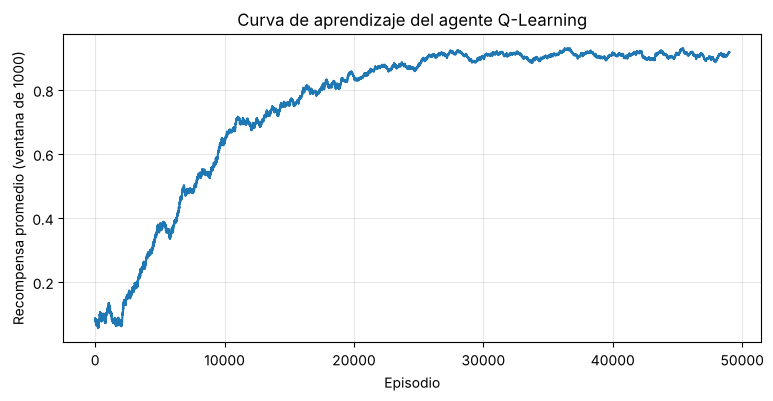

In [18]:
# Grafica la curva de aprendizaje del entrenamiento anterior
plt.figure(figsize=(9, 4))
plt.plot(media_movil(recompensas, 1000))
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio (ventana de 1000)")
plt.title("Curva de aprendizaje del agente Q-Learning")
plt.grid(alpha=0.3)
plt.show()

**Pregunta de reflexión 2:** Describe la forma de la curva. ¿Por qué crees que la recompensa promedio **empieza baja** y luego sube? ¿Qué papel juega que ε empiece en 1.0?

*Tu respuesta:*

La curva empieza cerca de 0.1, que es lo que se espera de un agente que juega casi al azar, y va subiendo poco a poco hasta llegar a casi 0.9 alrededor del episodio 25,000, donde se estabiliza. Empieza baja porque la tabla Q está llena de ceros y con ε = 1.0 el agente solo juega al azar, o sea que todavía no usa nada de lo que ha aprendido. Conforme ε baja, el agente empieza a elegir las jugadas que ya sabe que son buenas y la recompensa promedio sube. Además, esta recompensa se mide durante el entrenamiento, así que todavía incluye jugadas aleatorias y por eso no llega a 1. Que ε empiece en 1.0 sirve para que al inicio pruebe muchas jugadas y visite muchos estados distintos antes de decidirse por lo que le parece mejor.


---
**Pregunta de reflexión 3:** Con ε = 1.0 al principio el agente juega completamente al azar. ¿Por qué aun así aprende? (Piensa en qué sucede con la recompensa al final de cada partida y cómo se *propaga* hacia estados anteriores mediante el término $\gamma \max_{a'} Q(s',a')$.)

 *Tu respuesta:*

Aunque juegue al azar, todas las partidas terminan en ganar, perder o empatar, y esa recompensa sí se guarda en la tabla: en la última jugada Q(s,a) se acerca a +1, -1 o 0.5. Después, cuando el agente pasa otra vez por el estado anterior, el objetivo incluye γ·max Q(s',a'), entonces el valor del estado final se le pasa al estado anterior (multiplicado por γ), y luego al anterior a ese. De esta forma la recompensa se va propagando hacia atrás, jugada por jugada, hasta los estados del inicio de la partida. Además, Q-Learning aprende con el mejor valor posible del siguiente estado (el max) y no con lo que el agente realmente jugó, por eso puede aprender aunque sus jugadas sean aleatorias.


## 6. Experimentación con hiperparámetros

### EJERCICIO 8 — ¿Qué tanto importan α, γ y ε?

Escribe código que entrene **un agente por cada configuración** de la tabla y registre su tasa de victorias (con `evaluar`). Usa **20 000 episodios** por configuración para que sea rápido.

| Nombre | alpha | gamma | eps_inicio | eps_decay |
|---|---|---|---|---|
| base | 0.1 | 0.9 | 1.0 | 0.9998 |
| alpha bajo | 0.01 | 0.9 | 1.0 | 0.9998 |
| alpha alto | 0.9 | 0.9 | 1.0 | 0.9998 |
| gamma = 0 | 0.1 | 0.0 | 1.0 | 0.9998 |
| sin exploración | 0.1 | 0.9 | 0.05 | 1.0 *(ε se queda fijo en 0.05)* |

Al final:
1. Imprime una tabla con la **tasa de victorias** y **derrotas** de cada configuración.
2. Grafica las curvas de aprendizaje (media móvil) de todas en una sola figura.

💡 *Pista:* define las configuraciones en una lista de diccionarios y recórrelas con un `for`. Recuerda que `entrenar` recibe `eps_inicio` y `eps_decay`: ajústalos según la tabla.

Configuración      Victorias   Empates  Derrotas
------------------------------------------------
base                   0.882     0.099     0.018
alpha bajo             0.912     0.077     0.011
alpha alto             0.908     0.068     0.024
gamma = 0              0.703     0.154     0.143
sin exploración        0.805     0.169     0.026


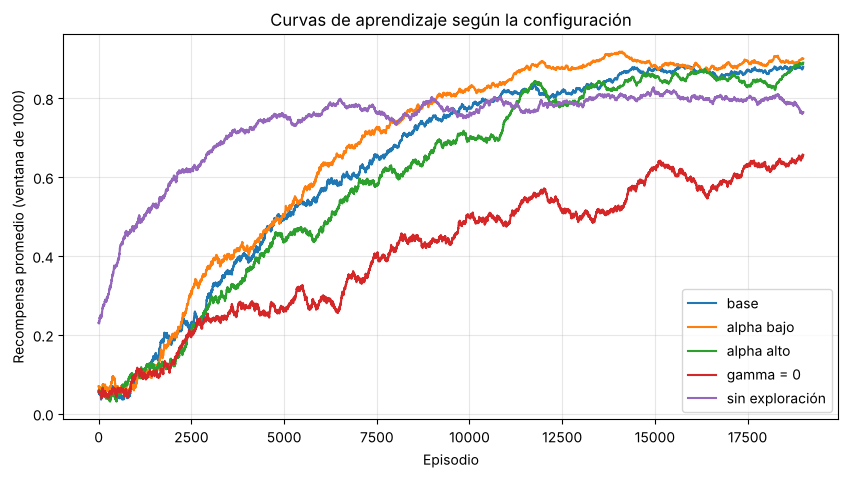

In [19]:
configuraciones = [
    {"nombre": "base",            "alpha": 0.1,  "gamma": 0.9, "eps_inicio": 1.0,  "eps_decay": 0.9998},
    {"nombre": "alpha bajo",      "alpha": 0.01, "gamma": 0.9, "eps_inicio": 1.0,  "eps_decay": 0.9998},
    {"nombre": "alpha alto",      "alpha": 0.9,  "gamma": 0.9, "eps_inicio": 1.0,  "eps_decay": 0.9998},
    {"nombre": "gamma = 0",       "alpha": 0.1,  "gamma": 0.0, "eps_inicio": 1.0,  "eps_decay": 0.9998},
    {"nombre": "sin exploración", "alpha": 0.1,  "gamma": 0.9, "eps_inicio": 0.05, "eps_decay": 1.0},
]

resultados = {}   # nombre -> (metricas_evaluacion, curva_de_recompensas)

for cfg in configuraciones:
    random.seed(42); np.random.seed(42)
    env_cfg = Gato()
    Q_cfg, rec_cfg = entrenar(env_cfg, n_episodios=20_000,
                              alpha=cfg["alpha"], gamma=cfg["gamma"],
                              eps_inicio=cfg["eps_inicio"], eps_decay=cfg["eps_decay"])
    metricas = evaluar(env_cfg, Q_cfg, n_partidas=2000)
    resultados[cfg["nombre"]] = (metricas, rec_cfg)

# Tabla de resultados
print(f"{'Configuración':<18}{'Victorias':>10}{'Empates':>10}{'Derrotas':>10}")
print("-" * 48)
for nombre, (m, _) in resultados.items():
    print(f"{nombre:<18}{m['victorias']:>10.3f}{m['empates']:>10.3f}{m['derrotas']:>10.3f}")

# Curvas de aprendizaje
plt.figure(figsize=(10, 5))
for nombre, (_, rec) in resultados.items():
    plt.plot(media_movil(rec, 1000), label=nombre)
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio (ventana de 1000)")
plt.title("Curvas de aprendizaje según la configuración")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [20]:
# Pruebas del Ejercicio 8
assert len(resultados) >= 4, "Entrena y guarda al menos 4 configuraciones distintas"
assert all(isinstance(v[0], dict) for v in resultados.values()), "Guarda el diccionario devuelto por evaluar()"
print("Ejercicio 8 completado")

Ejercicio 8 completado


**Pregunta de reflexión 4:** Analiza tu tabla y tus curvas y responde:
- a) ¿Qué ocurrió con `alpha` muy bajo y muy alto? ¿Por qué?
- b) ¿Qué le pasa al agente cuando `gamma = 0`? ¿Qué tipo de jugadas le cuesta aprender y por qué? *(Piensa: ¿cuándo recibe recompensa distinta de 0?)*
- c) ¿Qué efecto tuvo quitar la exploración?

*Tus respuestas:*

**a) alpha.** Con alpha bajo (0.01) obtuvo 0.912 de victorias y con alpha alto (0.9) 0.908, contra 0.882 de la base. Esperaba que alpha = 0.01 aprendiera mucho más lento y que alpha = 0.9 fuera inestable, pero los tres resultados quedaron parecidos. En las curvas sí se nota que la de alpha alto (verde) va por debajo de las demás casi todo el entrenamiento y sube con más altibajos, mientras que la de alpha bajo (naranja) incluso va arriba de la base. Creo que con 20,000 episodios alpha bajo tuvo tiempo suficiente de aprender, y como el oponente es aleatorio, un alpha pequeño promedia mejor los resultados distintos de una misma jugada. Como cada configuración se entrenó una sola vez, no sabemos si diferencias tan pequeñas (0.88 a 0.91) son reales o solo variación por el azar.

**b) gamma = 0.** El agente solo toma en cuenta la recompensa inmediata. Terminó con 0.703 de victorias y 0.143 de derrotas, mucho peor que las demás, y su curva sube más lento y se queda cerca de 0.65. La recompensa solo es distinta de 0 al terminar la partida, así que con gamma = 0 esa información nunca pasa a los estados anteriores. Solo aprende a ganar o a no perder en la jugada final, pero le cuesta aprender jugadas que preparan el triunfo más adelante, como crear una doble amenaza o tomar el centro al inicio.

**c) Sin exploración.** Con ε fijo en 0.05 el agente aprendió muy rápido al principio (su curva sube más que las demás en los primeros 5,000 episodios), pero después se estancó cerca de 0.8 y terminó con 0.805 de victorias, menos que las configuraciones con exploración (0.88 a 0.91). Como casi siempre repite la jugada que mejor le ha ido hasta ese momento, casi no prueba alternativas y puede quedarse con jugadas buenas pero no las mejores. También tuvo la tasa de empates más alta (0.169), lo que puede indicar que se conforma con empatar en situaciones donde podría ganar.


## 7. ¡Juega contra tu agente! *(código proporcionado)*

El agente juega con `X` (usando su política greedy) y tú con `O`. Escribe el número de la casilla donde quieras jugar.

In [21]:
def jugar_contra_agente(Q):
    juego = Gato()
    juego.reset(agente_empieza=True)
    while not juego.terminado:
        s = juego.estado()
        a = mejor_accion(Q, s, juego.acciones_disponibles())
        juego._mover(a, 1)
        print(f"El agente juega en la casilla {a}")
        juego.mostrar()
        if juego.terminado:
            break
        while True:
            try:
                mov = int(input("Tu jugada (0-8): "))
                if mov in juego.acciones_disponibles():
                    break
            except ValueError:
                pass
            print("Movimiento inválido, intenta de nuevo.")
        juego._mover(mov, -1)
        juego.mostrar()
    print({1: "Ganó el agente", -1: "¡Ganaste tú!", 0: "Empate"}[juego.ganador])

# Descomenta para jugar:
# jugar_contra_agente(Q)

**Pregunta de reflexión 5:** Juega varias partidas contra tu agente. ¿Es imbatible? Recuerda contra *quién* entrenó. ¿Qué tipo de jugadas del oponente humano podrían no haberse visto nunca durante el entrenamiento? ¿Cómo podrías mejorarlo?

*Tu respuesta:*

No es imbatible. Contra el oponente aleatorio casi nunca pierde (0.7% de derrotas), pero eso solo demuestra que juega bien contra alguien que mueve sin pensar. Un humano que juegue con estrategia puede hacer jugadas que el oponente aleatorio casi nunca hace, como bloquear siempre o armar una doble amenaza (dos formas de ganar a la vez). Esos tableros pudieron no aparecer nunca durante el entrenamiento, y en un estado nuevo todos los valores Q valen 0, así que el agente elige al azar entre todas las casillas y puede equivocarse. Para mejorarlo se podría entrenar contra un oponente más listo (reto 1) o contra sí mismo (self-play), usar más episodios, o aprovechar las simetrías del tablero para que aprenda más rápido.


## 8. Retos opcionales (puntos extra)

1. **Oponente inteligente.** Escribe una función `oponente_listo(env)` que (a) gane si puede ganar en una jugada, (b) bloquee si el agente está a punto de ganar, (c) en otro caso juegue al azar. Entrena con `Gato(oponente=oponente_listo)` y compara contra el agente entrenado con oponente aleatorio.
2. **Auto-juego (self-play).** Haz que dos agentes con tablas Q distintas jueguen entre sí y aprendan mutuamente.
3. **Simetrías.** El tablero tiene 8 simetrías (rotaciones y reflexiones). Reduce el número de estados haciendo que estados simétricos compartan Q.
4. **Recompensas.** Cambia la recompensa de empate (`R_EMPATE`) a `0` o a `-0.5`. ¿Cambia el comportamiento del agente? ¿Por qué?
5. **SARSA.** Modifica `actualizar_q` para que use la acción realmente elegida en $s'$ en vez del `max`. Esto es el algoritmo **SARSA** (*on-policy*). ¿En qué se diferencia de Q-Learning (*off-policy*)?
6. **Visualiza.** Muestra como mapa de calor (9 casillas) los valores Q del tablero vacío. ¿Qué casilla prefiere abrir tu agente?

## 9. Entregable y rúbrica sugerida

| Criterio | Puntos |
|---|---|
| Ejercicios 1–4 (tabla Q, mejor acción, ε-greedy, actualización) pasan las pruebas | 40 |
| Ejercicios 5–6 (entrenamiento y evaluación) pasan las pruebas | 20 |
| Ejercicios 7–8 (curva de aprendizaje y experimentos) | 15 |
| Preguntas de reflexión 1–5 (claridad y razonamiento) | 20 |
| Orden y legibilidad del código | 5 |
| **Retos opcionales** | **+10** |

**Entrega:** este notebook con todas las celdas ejecutadas y las respuestas escritas.